In [3]:
%pip install tensorflow matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Flatten, Dense

print("done")

done


In [11]:
train_data = pd.read_csv('mnist_train.csv')
test_data = pd.read_csv('mnist_test.csv')

In [12]:
print(train_data.head)

<bound method NDFrame.head of        label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0          5    0    0    0    0    0    0    0    0    0  ...      0      0   
1          0    0    0    0    0    0    0    0    0    0  ...      0      0   
2          4    0    0    0    0    0    0    0    0    0  ...      0      0   
3          1    0    0    0    0    0    0    0    0    0  ...      0      0   
4          9    0    0    0    0    0    0    0    0    0  ...      0      0   
...      ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...    ...    ...   
59995      8    0    0    0    0    0    0    0    0    0  ...      0      0   
59996      3    0    0    0    0    0    0    0    0    0  ...      0      0   
59997      5    0    0    0    0    0    0    0    0    0  ...      0      0   
59998      6    0    0    0    0    0    0    0    0    0  ...      0      0   
59999      8    0    0    0    0    0    0    0    0    0  ...      0      0   

       28

In [13]:
#separate features and labels
X_train = train_data.iloc[:, 1:].values  #features
y_train = train_data.iloc[:, 0].values   #labels

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [14]:
#normalize the features
X_train = X_train / 255.0
X_test = X_test / 255.0

In [22]:
#define the FNN architecture
model = Sequential([
    Flatten(input_shape=(784,)),  #wrote input_size instead of input_shape
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])


In [27]:
#compile the model
model.compile(
    optimizer=SGD(learning_rate=0.01),  #he athvat navta
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("done..")

done..


In [28]:
#train the model
history = model.fit(
    X_train, y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1  #he athvat navta
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8229 - loss: 0.6659 - val_accuracy: 0.9213 - val_loss: 0.2847
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9109 - loss: 0.3114 - val_accuracy: 0.9358 - val_loss: 0.2244
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9271 - loss: 0.2572 - val_accuracy: 0.9440 - val_loss: 0.1943
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9363 - loss: 0.2216 - val_accuracy: 0.9523 - val_loss: 0.1688
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9436 - loss: 0.1952 - val_accuracy: 0.9595 - val_loss: 0.1534
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9503 - loss: 0.1737 - val_accuracy: 0.9647 - val_loss: 0.1393
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9551 - loss: 0.1569 - val_accuracy: 0.9660 - val_loss: 0.1330
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9591 - loss: 0.142

In [30]:
#evaluate
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss: ", test_loss)
print("Test accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9654 - loss: 0.1169
Test Loss:  0.1169256865978241
Test accuracy: 96.5399980545044 %


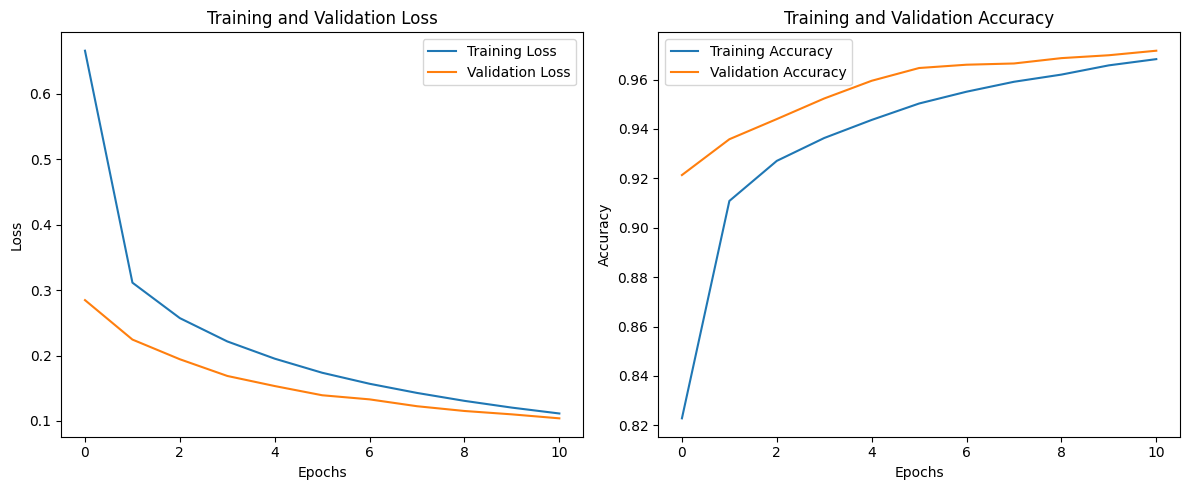

In [31]:
#plot

plt.figure(figsize=(12, 5))

#Loss
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

#Accuracy
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label="Training Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()